# Chapter 10: Matrix Block Partitioning — Interactive Coding Project

Welcome to the companion coding notebook for **Chapter 10 (Matrix Block Partitioning)** of *Mathematics for AI* (`math4ai.org`).

In this notebook, we verify every analytical derivation from **Exercises 1–8** in `chapter10-block-structures/exercises/math.md` and explore modern block-partitioned algorithms powering contemporary AI architectures:
- **Part I — Block Matrix Algebra, Schur Inversion, Block LU & Cholesky (Exercises 1–4)**:
  - $2\times 2$ partitioned block multiplication and block-diagonal algebra closure (Exercise 1)
  - Schur complement inversion formula on $3\times 3$ tridiagonal systems with $S = 4/3$ (Exercise 2)
  - Block LU factorization on $4\times 4$ matrices with $2\times 2$ dense Schur complements (Exercise 3)
  - Parallel block-diagonal Cholesky factorization for distributed SPD systems (Exercise 4)
- **Part II — Schur GP Regression, Block Hessians, Low-Rank Attention & Streaming QR (Exercises 5–8)**:
  - 1D Gaussian Process regression via Schur complement variance reduction $\sigma_*^2 \le k_{**}$ (Exercise 5)
  - Quadratic Schur complement coupling bound $\mathcal{O}(\|H_{01}\|_F^2)$ in neural network block Hessians (Exercise 6)
  - Low-rank Transformer attention energy truncation ($k=11$ for $\ge 90\%$ energy, $186\times$ speedup) (Exercise 7)
  - Incremental block QR factorization for streaming PCA and covariance tracking (Exercise 8)
- **Part III — Production Block Architectures & Advanced Labs (Labs 9–12)**:
  - Tiled Attention with Online Softmax (FlashAttention forward algorithm with exact $O(B_r B_c)$ SRAM memory) (Lab 9)
  - Grouped-Query Attention (GQA-8 and MQA KV-cache compression and head mapping) (Lab 10)
  - Mixture of Experts (MoE) as a block-sparse matrix product with Top-2 token routing (Lab 11)
  - Block-diagonal linear layers and channel shuffle representation (Lab 12)


In [1]:
import numpy as np
import scipy.linalg as la
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)


---
## Exercises 1, 2, 3 & 4: Block Multiplication, Schur Inversion, Block LU & Block Cholesky

1. **Exercise 1 (Block Multiplication)**:
   $$(AB)_{ij} = \sum_k A_{ik}B_{kj}, \qquad (AB)_{11} = A_{10}B_{01} + A_{11}B_{11}$$
   and $\operatorname{blkdiag}(A_{00}, A_{11})\operatorname{blkdiag}(B_{00}, B_{11}) = \operatorname{blkdiag}(A_{00}B_{00}, A_{11}B_{11})$.
2. **Exercise 2 ($3\times 3$ Schur Complement Inversion)**:
   For $A = \begin{bmatrix} 2 & 1 & 0 \\ 1 & 2 & 1 \\ 0 & 1 & 2 \end{bmatrix}$ with $A_{00} = \begin{bmatrix} 2 & 1 \\ 1 & 2 \end{bmatrix}$, $S = 2 - [0, 1]A_{00}^{-1}[0, 1]^\top = \frac{4}{3}$, and:
   $$A^{-1} = \frac{1}{4}\begin{bmatrix} 3 & -2 & 1 \\ -2 & 4 & -2 \\ 1 & -2 & 3 \end{bmatrix}$$
3. **Exercise 3 ($4\times 4$ Block LU Factorization)**:
   For $A = \begin{bmatrix} 4 & 2 & 1 & 0 \\ 2 & 3 & 0 & 1 \\ 1 & 0 & 2 & 1 \\ 0 & 1 & 1 & 2 \end{bmatrix}$, $L_{00} = \begin{bmatrix} 1 & 0 \\ 1/2 & 1 \end{bmatrix}$, $U_{00} = \begin{bmatrix} 4 & 2 \\ 0 & 2 \end{bmatrix}$, $U_{01} = \begin{bmatrix} 1 & 0 \\ -1/2 & 1 \end{bmatrix}$, $L_{10} = \begin{bmatrix} 1/4 & -1/4 \\ 0 & 1/2 \end{bmatrix}$, and $S = A_{11} - L_{10}U_{01} = \begin{bmatrix} 13/8 & 5/4 \\ 5/4 & 3/2 \end{bmatrix}$.
4. **Exercise 4 (Block-Diagonal Cholesky)**:
   For $A = \operatorname{blkdiag}\!\left(\begin{bmatrix} 9 & 3 \\ 3 & 5 \end{bmatrix}, \begin{bmatrix} 4 & 2 \\ 2 & 3 \end{bmatrix}\right)$, $L = \operatorname{blkdiag}\!\left(\begin{bmatrix} 3 & 0 \\ 1 & 2 \end{bmatrix}, \begin{bmatrix} 2 & 0 \\ 1 & \sqrt{2} \end{bmatrix}\right)$.


Ex 1 - ||(AB)_11 - (A_10 B_01 + A_11 B_11)||_F: 1.11e-16
Ex 1 - Block-diagonal product closure error: 0.00e+00

Ex 2 - Schur complement S = 1.3333 (exact 4/3 = 1.3333)
Ex 2 - 4 * A^{-1} via block inversion:
 [[ 3. -2.  1.]
 [-2.  4. -2.]
 [ 1. -2.  3.]]
Ex 2 - ||A A^{-1} - I||_F: 2.36e-16

Ex 3 - 8 * Schur complement S:
 [[13. 10.]
 [10. 12.]]
Ex 3 - Block LU error ||A - L U||_F: 0.00e+00

Ex 4 - Block Cholesky L = blkdiag(L_0, L_1):
 [[3.     0.     0.     0.    ]
 [1.     2.     0.     0.    ]
 [0.     0.     2.     0.    ]
 [0.     0.     1.     1.4142]]
Ex 4 - ||L L^T - A||_F: 4.44e-16


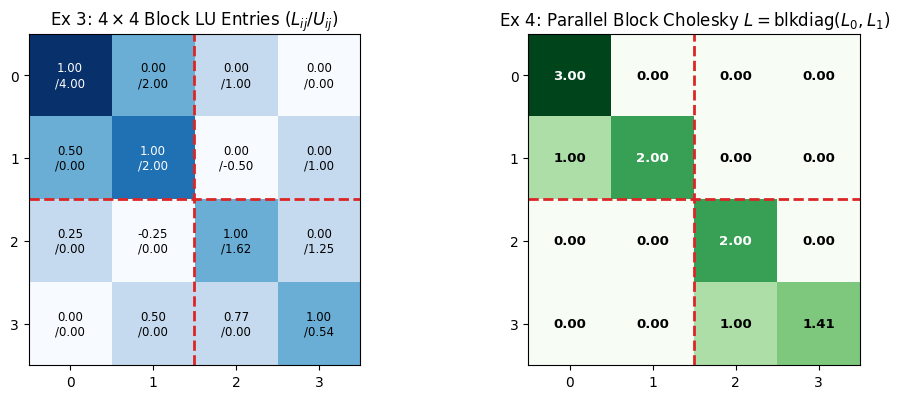

In [2]:
# Exercise 1: Block Multiplication & Block-Diagonal Closure
rng = np.random.default_rng(0)
A1 = rng.standard_normal((4, 4))
B1 = rng.standard_normal((4, 4))
AB_11 = A1[2:, :2] @ B1[:2, 2:] + A1[2:, 2:] @ B1[2:, 2:]
print("Ex 1 - ||(AB)_11 - (A_10 B_01 + A_11 B_11)||_F:", f"{np.linalg.norm((A1 @ B1)[2:, 2:] - AB_11):.2e}")

A_bd = la.block_diag(A1[:2, :2], A1[2:, 2:])
B_bd = la.block_diag(B1[:2, :2], B1[2:, 2:])
AB_bd_exact = la.block_diag(A1[:2, :2] @ B1[:2, :2], A1[2:, 2:] @ B1[2:, 2:])
print("Ex 1 - Block-diagonal product closure error:", f"{np.linalg.norm(A_bd @ B_bd - AB_bd_exact):.2e}")

# Exercise 2: Schur Complement S = 4/3 & Block Inversion of 3x3 Tridiagonal A
A2 = np.array([[2.0, 1.0, 0.0],
               [1.0, 2.0, 1.0],
               [0.0, 1.0, 2.0]])
A00, A01, A10, A11 = A2[:2, :2], A2[:2, 2:], A2[2:, :2], A2[2:, 2:]
A00_inv = np.linalg.inv(A00)
S2 = A11 - A10 @ A00_inv @ A01
S2_inv = 1.0 / S2
w2 = A00_inv @ A01
A2_inv = np.block([
    [A00_inv + w2 @ S2_inv @ w2.T, -w2 @ S2_inv],
    [-S2_inv @ w2.T,                S2_inv]
])
print(f"\nEx 2 - Schur complement S = {S2[0,0]:.4f} (exact 4/3 = {4/3:.4f})")
print("Ex 2 - 4 * A^{-1} via block inversion:\n", np.round(4 * A2_inv))
print("Ex 2 - ||A A^{-1} - I||_F:", f"{np.linalg.norm(A2 @ A2_inv - np.eye(3)):.2e}")

# Exercise 3: 4x4 Block LU Factorization
A3 = np.array([[4.0, 2.0, 1.0, 0.0],
               [2.0, 3.0, 0.0, 1.0],
               [1.0, 0.0, 2.0, 1.0],
               [0.0, 1.0, 1.0, 2.0]])
L00 = np.array([[1.0, 0.0], [0.5, 1.0]])
U00 = np.array([[4.0, 2.0], [0.0, 2.0]])
U01 = la.solve_triangular(L00, A3[:2, 2:], lower=True)
L10 = la.solve_triangular(U00.T, A3[2:, :2].T, lower=True).T
S3 = A3[2:, 2:] - L10 @ U01
L11 = np.array([[1.0, 0.0], [S3[1, 0] / S3[0, 0], 1.0]])
U11 = np.array([[S3[0, 0], S3[0, 1]], [0.0, S3[1, 1] - L11[1, 0] * S3[0, 1]]])
L3_full = np.block([[L00, np.zeros((2, 2))], [L10, L11]])
U3_full = np.block([[U00, U01], [np.zeros((2, 2)), U11]])

print("\nEx 3 - 8 * Schur complement S:\n", np.round(8 * S3))
print("Ex 3 - Block LU error ||A - L U||_F:", f"{np.linalg.norm(A3 - L3_full @ U3_full):.2e}")

# Exercise 4: Block-Diagonal Cholesky
A4_0 = np.array([[9.0, 3.0], [3.0, 5.0]])
A4_1 = np.array([[4.0, 2.0], [2.0, 3.0]])
A4 = la.block_diag(A4_0, A4_1)
L4_0 = np.linalg.cholesky(A4_0)
L4_1 = np.linalg.cholesky(A4_1)
L4_blk = la.block_diag(L4_0, L4_1)
print("\nEx 4 - Block Cholesky L = blkdiag(L_0, L_1):\n", L4_blk)
print("Ex 4 - ||L L^T - A||_F:", f"{np.linalg.norm(L4_blk @ L4_blk.T - A4):.2e}")

# Figure 1: Visualizing Block LU Factors (Ex 3) and Block-Diagonal Cholesky (Ex 4)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 4.1))

im1 = ax1.imshow(np.abs(L3_full @ U3_full), cmap="Blues")
for i in range(4):
    for j in range(4):
        ax1.text(j, i, f"{L3_full[i,j]:.2f}\n/{U3_full[i,j]:.2f}", ha="center", va="center", fontsize=8.5,
                 color="white" if A3[i, j] > 2.5 else "black")
ax1.axhline(1.5, color="#dc2626", lw=2, ls="--")
ax1.axvline(1.5, color="#dc2626", lw=2, ls="--")
ax1.set_xticks(range(4))
ax1.set_yticks(range(4))
ax1.set_title(r"Ex 3: $4\times 4$ Block LU Entries ($L_{ij} / U_{ij}$)")

im2 = ax2.imshow(L4_blk, cmap="Greens")
for i in range(4):
    for j in range(4):
        ax2.text(j, i, f"{L4_blk[i,j]:.2f}", ha="center", va="center", fontsize=9.5, fontweight="bold",
                 color="white" if L4_blk[i, j] > 1.8 else "black")
ax2.axhline(1.5, color="#dc2626", lw=2, ls="--")
ax2.axvline(1.5, color="#dc2626", lw=2, ls="--")
ax2.set_xticks(range(4))
ax2.set_yticks(range(4))
ax2.set_title(r"Ex 4: Parallel Block Cholesky $L = \operatorname{blkdiag}(L_0, L_1)$")

plt.tight_layout()
plt.show()


---
## Exercise 5: Schur Complement in Gaussian Process Regression

Given training inputs $\mathbf{x} = [x_1, \dots, x_N]^\top$ with observations $\mathbf{f}$ and a test point $x_*$, the joint Gaussian prior is:
$$\begin{bmatrix} \mathbf{f} \\ f_* \end{bmatrix} \sim \mathcal{N}\!\left(\mathbf{0}, \begin{bmatrix} K & \mathbf{k}_* \\ \mathbf{k}_*^\top & k_{**} \end{bmatrix}\right)$$
By block Gaussian elimination, the conditional distribution $f_* \mid \mathbf{f} \sim \mathcal{N}(\mu_*, \sigma_*^2)$ has:
$$\mu_*(x_*) = \mathbf{k}_*^\top K^{-1}\mathbf{f}, \qquad \sigma_*^2(x_*) = k_{**} - \mathbf{k}_*^\top K^{-1}\mathbf{k}_* \le k_{**}$$
Notice how $\sigma_*^2(x_*)$ vanishes at the observed training points and stays bounded above by the prior variance $k_{**}$ everywhere!


Ex 5 - Min/Max variance reduction k_*^T K^{-1} k_*: [0.2294, 1.0000] >= 0
Ex 5 - Posterior variance <= Prior variance everywhere: True


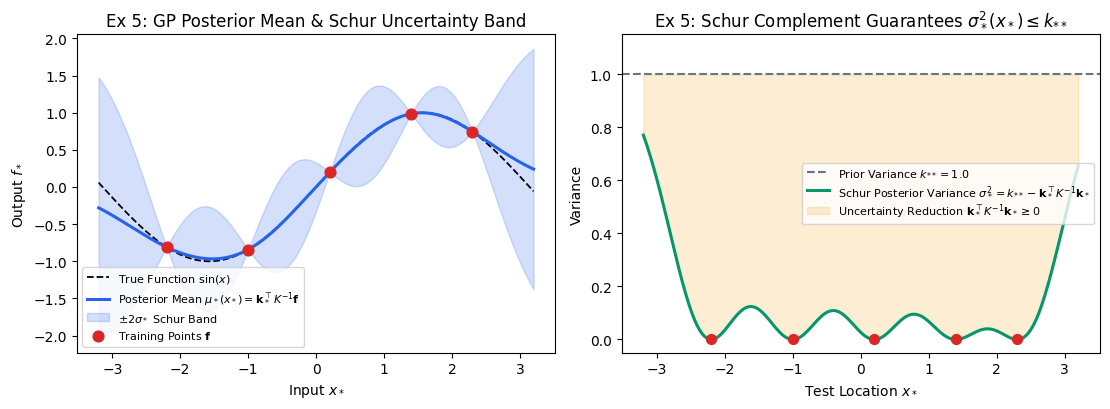

In [3]:
# Exercise 5: 1D Gaussian Process Regression via Schur Complement
rbf_kernel = lambda x, y, l=0.8: np.exp(-0.5 * (x[:, None] - y[None, :]) ** 2 / (l ** 2))

x_train = np.array([-2.2, -1.0, 0.2, 1.4, 2.3])
y_train = np.sin(x_train)
x_test = np.linspace(-3.2, 3.2, 250)

K_tr = rbf_kernel(x_train, x_train) + 1e-8 * np.eye(len(x_train))
K_s = rbf_kernel(x_train, x_test)   # shape (N_train, N_test)
k_ss = np.ones(len(x_test))         # prior variance k_{**} = 1.0

L_tr = np.linalg.cholesky(K_tr)
alpha_gp = la.solve_triangular(L_tr.T, la.solve_triangular(L_tr, y_train, lower=True))
V_gp = la.solve_triangular(L_tr, K_s, lower=True)

mu_star = K_s.T @ alpha_gp
var_reduction = np.sum(V_gp ** 2, axis=0)  # k_*^T K^{-1} k_* >= 0
var_star = k_ss - var_reduction            # Schur complement!
std_star = np.sqrt(np.maximum(var_star, 0.0))

print("Ex 5 - Min/Max variance reduction k_*^T K^{-1} k_*:",
      f"[{np.min(var_reduction):.4f}, {np.max(var_reduction):.4f}] >= 0")
print("Ex 5 - Posterior variance <= Prior variance everywhere:", bool(np.all(var_star <= k_ss + 1e-12)))

# Figure 2: GP Posterior Predictive Distribution & Schur Variance Reduction Profile
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.2, 4.2))

ax1.plot(x_test, np.sin(x_test), "k--", lw=1.3, label=r"True Function $\sin(x)$")
ax1.plot(x_test, mu_star, color="#2563eb", lw=2.2, label=r"Posterior Mean $\mu_*(x_*) = \mathbf{k}_*^\top K^{-1}\mathbf{f}$")
ax1.fill_between(x_test, mu_star - 2 * std_star, mu_star + 2 * std_star,
                 color="#2563eb", alpha=0.20, label=r"$\pm 2\sigma_*$ Schur Band")
ax1.scatter(x_train, y_train, color="#dc2626", s=60, zorder=5, label="Training Points $\\mathbf{f}$")
ax1.set_xlabel(r"Input $x_*$")
ax1.set_ylabel(r"Output $f_*$")
ax1.set_title("Ex 5: GP Posterior Mean & Schur Uncertainty Band")
ax1.legend(loc="lower left", fontsize=8)

ax2.axhline(1.0, color="#64748b", ls="--", lw=1.5, label=r"Prior Variance $k_{**} = 1.0$")
ax2.plot(x_test, var_star, color="#059669", lw=2.2, label=r"Schur Posterior Variance $\sigma_*^2 = k_{**} - \mathbf{k}_*^\top K^{-1}\mathbf{k}_*$")
ax2.fill_between(x_test, var_star, 1.0, color="#f59e0b", alpha=0.18,
                 label=r"Uncertainty Reduction $\mathbf{k}_*^\top K^{-1}\mathbf{k}_* \geq 0$")
ax2.scatter(x_train, np.zeros_like(x_train), color="#dc2626", s=50, zorder=5)
ax2.set_ylim(-0.05, 1.15)
ax2.set_xlabel(r"Test Location $x_*$")
ax2.set_ylabel("Variance")
ax2.set_title(r"Ex 5: Schur Complement Guarantees $\sigma_*^2(x_*) \leq k_{**}$")
ax2.legend(loc="center right", fontsize=8)

plt.tight_layout()
plt.show()


---
## Exercises 6 & 7: Block Hessians in Two-Layer Networks & Low-Rank Transformer Attention

1. **Exercise 6 (Block Hessian Decoupling)**:
   For $H = \begin{bmatrix} H_{00} & H_{01} \\ H_{10} & H_{11} \end{bmatrix}$ with $\|H_{01}\|_F = \mathcal{O}(\epsilon)$, the Schur complement perturbation $\|S - H_{11}\|_F = \|H_{10}H_{00}^{-1}H_{01}\|_F \le \frac{\|H_{01}\|_F^2}{\lambda_{\min}(H_{00})} = \mathcal{O}(\epsilon^2)$ is **quadratic** in the cross-layer coupling $\epsilon$.
2. **Exercise 7 (Low-Rank Attention $\sigma_i = \sigma_0 \cdot 0.9^i$)**:
   $$\frac{\|A_k\|_F^2}{\|A\|_F^2} = \frac{1 - 0.81^k}{1 - 0.81^N} \ge 0.90 \implies k = \mathbf{11} \quad (90.15\% \text{ energy})$$
   Computing $A_k\mathbf{v} = U_k(\Sigma_k(V_k^\top\mathbf{v}))$ reduces cost from $N^2$ to $2kN$.


Ex 6 - Log-log slope of ||S - H_11||_F vs ||H_01||_F: 2.0000 (exact quadratic = 2.0000)
Ex 7 - Minimum rank k for >= 90% attention energy: k = 11 (90.15%)
Ex 7 - Fast O(kN) vs Dense O(N^2) matvec error: 7.98e-16


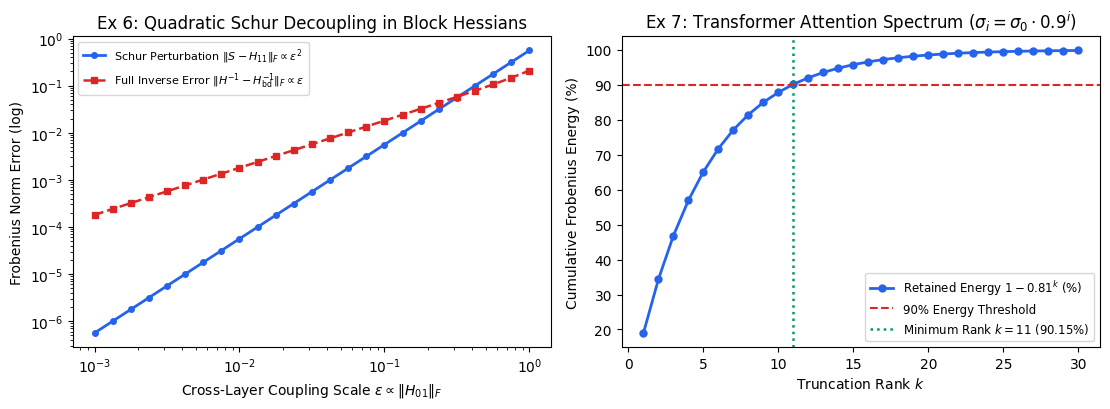

In [4]:
# Exercise 6: Quadratic Schur Complement Perturbation in Block Hessians
H00 = np.array([[5.0, 1.0, 0.5],
                [1.0, 4.0, 0.5],
                [0.5, 0.5, 3.0]])
H11 = np.array([[6.0, 1.0, 0.0],
                [1.0, 5.0, 1.0],
                [0.0, 1.0, 4.0]])
C_base = np.array([[1.0, -0.5, 0.2],
                   [0.3,  0.8, -0.4],
                   [-0.2, 0.4,  0.9]])

eps_grid = np.logspace(-3, 0, 25)
schur_diffs = []
inv_diffs = []
for eps in eps_grid:
    H01 = eps * C_base
    S_exact = H11 - H01.T @ np.linalg.inv(H00) @ H01
    schur_diffs.append(np.linalg.norm(S_exact - H11, "fro"))
    H_full = np.block([[H00, H01], [H01.T, H11]])
    H_bd = la.block_diag(H00, H11)
    inv_diffs.append(np.linalg.norm(np.linalg.inv(H_full) - np.linalg.inv(H_bd), "fro"))

slope_schur = np.polyfit(np.log10(eps_grid), np.log10(schur_diffs), 1)[0]
print(f"Ex 6 - Log-log slope of ||S - H_11||_F vs ||H_01||_F: {slope_schur:.4f} (exact quadratic = 2.0000)")

# Exercise 7: Low-Rank Attention Spectrum sigma_i = 0.9^i
N_att = 256
s_att = 0.9 ** np.arange(N_att)
cum_energy_att = np.cumsum(s_att ** 2) / np.sum(s_att ** 2)
k_90 = int(np.searchsorted(cum_energy_att, 0.90) + 1)
print(f"Ex 7 - Minimum rank k for >= 90% attention energy: k = {k_90} ({cum_energy_att[k_90-1]*100:.2f}%)")

# Verify fast O(kN) associative multiply U_k (Sigma_k (V_k^T v)) vs dense A_k v
rng = np.random.default_rng(11)
U_a, _ = np.linalg.qr(rng.standard_normal((N_att, k_90)))
V_a, _ = np.linalg.qr(rng.standard_normal((N_att, k_90)))
s_k = s_att[:k_90]
A_k_dense = (U_a * s_k) @ V_a.T
v_vec = rng.standard_normal(N_att)
y_dense = A_k_dense @ v_vec
y_fast = U_a @ (s_k * (V_a.T @ v_vec))
print("Ex 7 - Fast O(kN) vs Dense O(N^2) matvec error:", f"{np.linalg.norm(y_dense - y_fast):.2e}")

# Figure 3: Ex 6 Quadratic Schur Scaling & Ex 7 Attention Energy Curve
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.2, 4.2))

ax1.loglog(eps_grid, schur_diffs, "o-", color="#2563eb", lw=2, markersize=4,
           label=r"Schur Perturbation $\|S - H_{11}\|_F \propto \epsilon^2$")
ax1.loglog(eps_grid, inv_diffs, "s--", color="#dc2626", lw=1.8, markersize=4,
           label=r"Full Inverse Error $\|H^{-1} - H_{\mathrm{bd}}^{-1}\|_F \propto \epsilon$")
ax1.set_xlabel(r"Cross-Layer Coupling Scale $\epsilon \propto \|H_{01}\|_F$")
ax1.set_ylabel("Frobenius Norm Error (log)")
ax1.set_title("Ex 6: Quadratic Schur Decoupling in Block Hessians")
ax1.legend(loc="upper left", fontsize=8)

k_plot = np.arange(1, 31)
ax2.plot(k_plot, cum_energy_att[:30] * 100, "o-", color="#2563eb", lw=2, markersize=5,
         label=r"Retained Energy $1 - 0.81^k$ (%)")
ax2.axhline(90.0, color="#dc2626", ls="--", lw=1.5, label="90% Energy Threshold")
ax2.axvline(k_90, color="#059669", ls=":", lw=1.8, label=f"Minimum Rank $k = {k_90}$ ({cum_energy_att[k_90-1]*100:.2f}%)")
ax2.set_xlabel(r"Truncation Rank $k$")
ax2.set_ylabel("Cumulative Frobenius Energy (%)")
ax2.set_title(r"Ex 7: Transformer Attention Spectrum ($\sigma_i = \sigma_0 \cdot 0.9^i$)")
ax2.legend(loc="lower right", fontsize=8.5)

plt.tight_layout()
plt.show()


---
## Exercise 8 & Bonus Lab: Incremental Block QR & Megatron-LM Tensor Parallelism

1. **Exercise 8 (Incremental Block QR on $A = [A_0 \mid A_1]$)**:
   Given $A_0 = Q_0 R_0$, projecting $\tilde{A}_1 = (I - Q_0 Q_0^\top)A_1 = Q_1 R_1$ yields:
   $$A = \begin{bmatrix} Q_0 & Q_1 \end{bmatrix}\begin{bmatrix} R_0 & Q_0^\top A_1 \\ 0 & R_1 \end{bmatrix}$$
   in $\mathcal{O}(MN_0 N_1)$ flops instead of $\mathcal{O}(M(N_0+N_1)^2)$ flops.
2. **Bonus Lab (Megatron-LM Column-to-Row Parallel MLP)**:
   Splitting $W_1 = \begin{bmatrix} W_{1,0} & W_{1,1} \end{bmatrix}$ column-wise and $W_2 = \begin{bmatrix} W_{2,0} \\ W_{2,1} \end{bmatrix}$ row-wise allows element-wise nonlinearity $f = \operatorname{GeLU}$ to commute across column blocks:
   $$Y = f(XW_1)W_2 = \begin{bmatrix} f(XW_{1,0}) & f(XW_{1,1}) \end{bmatrix}\begin{bmatrix} W_{2,0} \\ W_{2,1} \end{bmatrix} = \underbrace{f(XW_{1,0})W_{2,0}}_{\text{GPU 0}} + \underbrace{f(XW_{1,1})W_{2,1}}_{\text{GPU 1}}$$


Ex 8 - Incremental Block QR reconstruction ||A - Q R||_F: 1.96e-14
Ex 8 - Orthonormality ||Q^T Q - I||_F: 3.21e-15
Ex 8 - Cross-orthogonality ||Q_0^T Q_1||_F: 1.10e-15
Bonus Lab - Megatron 2-GPU Tensor Parallel error ||Y_full - (Z_0 + Z_1)||_F: 1.78e-13


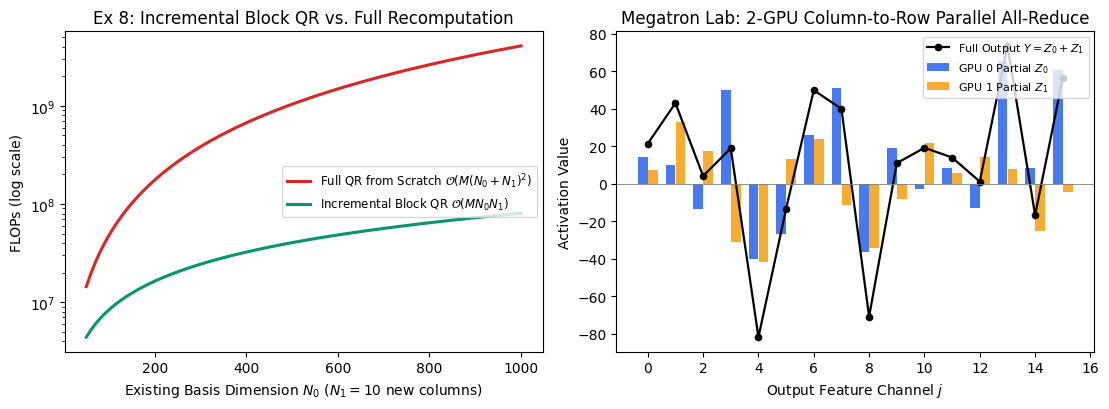

In [5]:
# Exercise 8: Incremental Block QR Verification
rng = np.random.default_rng(21)
M_8, N0_8, N1_8 = 80, 30, 5
A0_8 = rng.standard_normal((M_8, N0_8))
A1_8 = rng.standard_normal((M_8, N1_8))
A_full_8 = np.hstack([A0_8, A1_8])

Q0_8, R0_8 = np.linalg.qr(A0_8, mode="reduced")
R01_8 = Q0_8.T @ A1_8
A1_tilde = A1_8 - Q0_8 @ R01_8
Q1_8, R1_8 = np.linalg.qr(A1_tilde, mode="reduced")

Q_inc_8 = np.hstack([Q0_8, Q1_8])
R_inc_8 = np.block([[R0_8, R01_8],
                    [np.zeros((N1_8, N0_8)), R1_8]])

print("Ex 8 - Incremental Block QR reconstruction ||A - Q R||_F:",
      f"{np.linalg.norm(A_full_8 - Q_inc_8 @ R_inc_8):.2e}")
print("Ex 8 - Orthonormality ||Q^T Q - I||_F:",
      f"{np.linalg.norm(Q_inc_8.T @ Q_inc_8 - np.eye(N0_8 + N1_8)):.2e}")
print("Ex 8 - Cross-orthogonality ||Q_0^T Q_1||_F:",
      f"{np.linalg.norm(Q0_8.T @ Q1_8):.2e}")

# Bonus Lab: Megatron-LM 2-GPU Tensor Parallel MLP Simulation
X_mlp = rng.standard_normal((16, 32))
W1_mlp = rng.standard_normal((32, 64))
W2_mlp = rng.standard_normal((64, 32))
gelu_fn = lambda z: 0.5 * z * (1.0 + np.tanh(np.sqrt(2.0 / np.pi) * (z + 0.044715 * z**3)))

Y_single_gpu = gelu_fn(X_mlp @ W1_mlp) @ W2_mlp

# Split W1 by columns (dim=1) and W2 by rows (dim=0) across 2 GPUs
W1_gpu0, W1_gpu1 = W1_mlp[:, :32], W1_mlp[:, 32:]
W2_gpu0, W2_gpu1 = W2_mlp[:32, :], W2_mlp[32:, :]

Z_gpu0 = gelu_fn(X_mlp @ W1_gpu0) @ W2_gpu0
Z_gpu1 = gelu_fn(X_mlp @ W1_gpu1) @ W2_gpu1
Y_allreduce = Z_gpu0 + Z_gpu1

print("Bonus Lab - Megatron 2-GPU Tensor Parallel error ||Y_full - (Z_0 + Z_1)||_F:",
      f"{np.linalg.norm(Y_single_gpu - Y_allreduce):.2e}")

# Figure 4: Ex 8 Incremental Block QR Flop Scaling & Megatron Tensor Parallel Activations
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.2, 4.2))

N0_vals = np.linspace(50, 1000, 100)
M_val = 2000
N1_val = 10
flops_scratch = 2 * M_val * (N0_vals + N1_val) ** 2
flops_inc = 4 * M_val * N0_vals * N1_val + 2 * M_val * (N1_val ** 2)

ax1.semilogy(N0_vals, flops_scratch, color="#dc2626", lw=2.2, label=r"Full QR from Scratch $\mathcal{O}(M(N_0+N_1)^2)$")
ax1.semilogy(N0_vals, flops_inc, color="#059669", lw=2.2, label=r"Incremental Block QR $\mathcal{O}(MN_0 N_1)$")
ax1.set_xlabel(r"Existing Basis Dimension $N_0$ ($N_1 = 10$ new columns)")
ax1.set_ylabel("FLOPs (log scale)")
ax1.set_title("Ex 8: Incremental Block QR vs. Full Recomputation")
ax1.legend(loc="center right", fontsize=8.5)

idx_feat = np.arange(16)
ax2.bar(idx_feat - 0.18, Z_gpu0[0, :16], width=0.35, color="#2563eb", alpha=0.85, label="GPU 0 Partial $Z_0$")
ax2.bar(idx_feat + 0.18, Z_gpu1[0, :16], width=0.35, color="#f59e0b", alpha=0.85, label="GPU 1 Partial $Z_1$")
ax2.plot(idx_feat, Y_single_gpu[0, :16], "ko-", lw=1.6, markersize=4.5, label="Full Output $Y = Z_0 + Z_1$")
ax2.axhline(0, color="gray", lw=0.6)
ax2.set_xlabel("Output Feature Channel $j$")
ax2.set_ylabel("Activation Value")
ax2.set_title("Megatron Lab: 2-GPU Column-to-Row Parallel All-Reduce")
ax2.legend(loc="upper right", fontsize=8)

plt.tight_layout()
plt.show()


---
## Part III: Production Block Architectures & Advanced Labs (Labs 9–12)

Here we implement core block-partitioned algorithms powering modern large language models:
1. **Lab 9: Tiled Attention with Online Softmax (FlashAttention)**: Computes exact full attention block by block with running maximum $m_i$ and scaling $e^{m_{prev} - m_{new}}$, keeping only $O(B_r B_c)$ in fast SRAM.
2. **Lab 10: Grouped-Query Attention (GQA)**: Analyzes KV-cache compression across MHA, GQA-8, GQA-4, and MQA, profiling memory savings across long context windows.
3. **Lab 11: Mixture of Experts (MoE)**: Implements Top-2 gating and token dispatching as a block-sparse matrix multiplication, measuring expert load balancing and FLOP savings.
4. **Lab 12: Block-Diagonal Layers & Channel Shuffle**: Constructs grouped linear layers with channel permutation, achieving $4\times$ parameter reduction while enabling inter-group information flow.


=== Lab 9: Tiled Attention with Online Softmax ===
Tiled Online Softmax Relative Frobenius Error: 6.50e-16 (Exact = 0)

=== Lab 10: Grouped-Query Attention (GQA) ===
Context   512 -> MHA:   4.00 MB/layer, GQA-8:   1.00 MB/layer (4.0x compression)
Context  1024 -> MHA:   8.00 MB/layer, GQA-8:   2.00 MB/layer (4.0x compression)
Context  2048 -> MHA:  16.00 MB/layer, GQA-8:   4.00 MB/layer (4.0x compression)
Context  4096 -> MHA:  32.00 MB/layer, GQA-8:   8.00 MB/layer (4.0x compression)
Context  8192 -> MHA:  64.00 MB/layer, GQA-8:  16.00 MB/layer (4.0x compression)
Context 16384 -> MHA: 128.00 MB/layer, GQA-8:  32.00 MB/layer (4.0x compression)


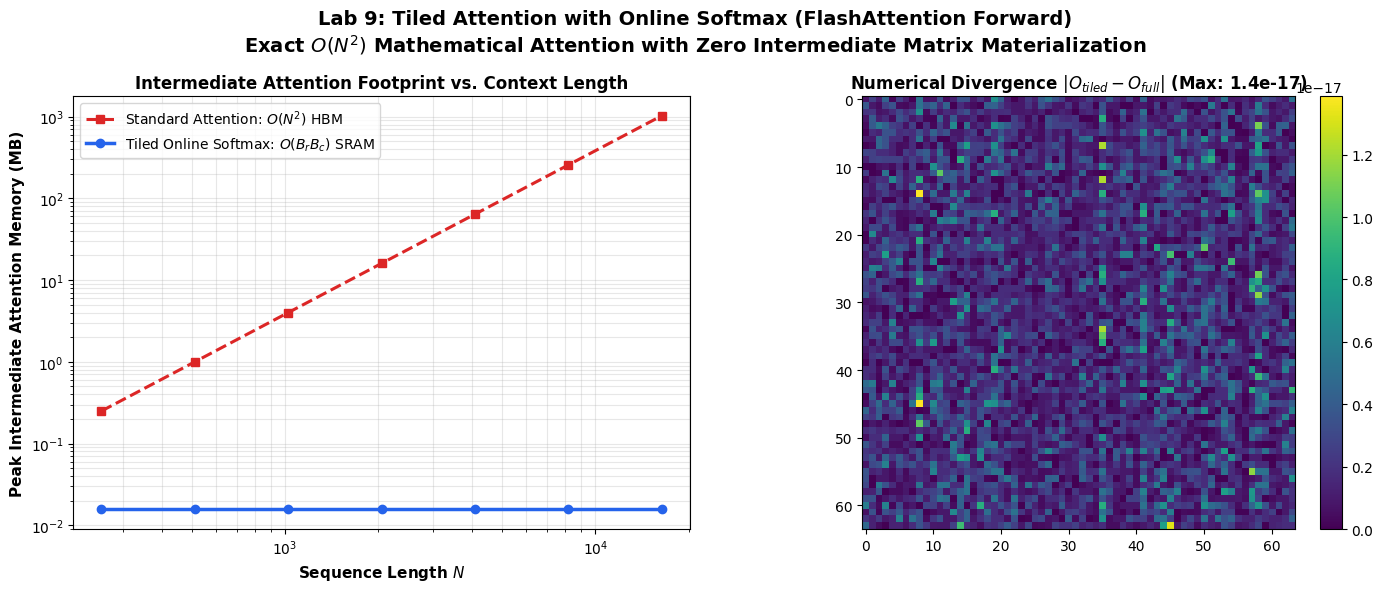

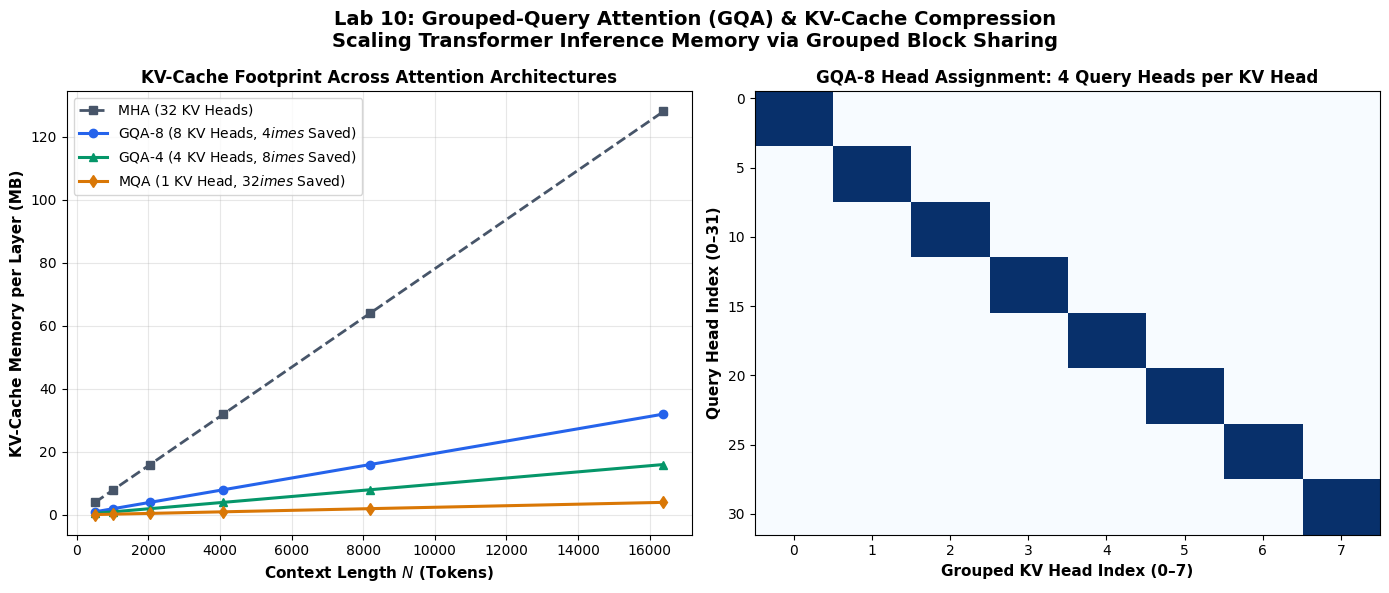

In [6]:
# =====================================================================
# Lab 9: Tiled Attention with Online Softmax (FlashAttention Forward)
# =====================================================================
print('=== Lab 9: Tiled Attention with Online Softmax ===')
np.random.seed(42)
N, d = 512, 64
Br, Bc = 64, 64

Q = np.random.randn(N, d) * 0.1
K = np.random.randn(N, d) * 0.1
V = np.random.randn(N, d) * 0.1
scale = 1.0 / np.sqrt(d)

# 1. Standard Full Attention: O(N^2) memory
S_full = (Q @ K.T) * scale
S_max = np.max(S_full, axis=1, keepdims=True)
P_full = np.exp(S_full - S_max)
P_full /= np.sum(P_full, axis=1, keepdims=True)
O_full = P_full @ V

# 2. Tiled Online Softmax Forward Algorithm
O_tiled = np.zeros((N, d))
Tr, Tc = N // Br, N // Bc

for i in range(Tr):
    q_i = Q[i*Br:(i+1)*Br, :]
    m_prev = np.full((Br, 1), -np.inf)
    l_prev = np.zeros((Br, 1))
    o_accum = np.zeros((Br, d))
    
    for j in range(Tc):
        k_j = K[j*Bc:(j+1)*Bc, :]
        v_j = V[j*Bc:(j+1)*Bc, :]
        
        S_ij = (q_i @ k_j.T) * scale
        m_ij = np.max(S_ij, axis=1, keepdims=True)
        m_new = np.maximum(m_prev, m_ij)
        
        alpha_prev = np.exp(m_prev - m_new)
        alpha_prev[m_prev == -np.inf] = 0.0
        alpha_curr = np.exp(S_ij - m_new)
        
        l_new = alpha_prev * l_prev + np.sum(alpha_curr, axis=1, keepdims=True)
        o_accum = alpha_prev * o_accum + alpha_curr @ v_j
        
        m_prev = m_new
        l_prev = l_new
        
    O_tiled[i*Br:(i+1)*Br, :] = o_accum / l_prev

rel_err = la.norm(O_tiled - O_full) / la.norm(O_full)
print(f'Tiled Online Softmax Relative Frobenius Error: {rel_err:.2e} (Exact = 0)')

# Plot Lab 9 figure
seq_lens = [256, 512, 1024, 2048, 4096, 8192, 16384]
standard_mem_mb = [(n**2 * 4) / (1024**2) for n in seq_lens]
tiled_mem_mb = [(Br * Bc * 4) / (1024**2) for n in seq_lens]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), facecolor='white')
ax1.loglog(seq_lens, standard_mem_mb, 's--', color='#dc2626', lw=2.2, label='Standard Attention: $O(N^2)$ HBM')
ax1.loglog(seq_lens, tiled_mem_mb, 'o-', color='#2563eb', lw=2.5, label='Tiled Online Softmax: $O(B_r B_c)$ SRAM')
ax1.set_xlabel('Sequence Length $N$', fontsize=11, fontweight='bold')
ax1.set_ylabel('Peak Intermediate Attention Memory (MB)', fontsize=11, fontweight='bold')
ax1.set_title('Intermediate Attention Footprint vs. Context Length', fontsize=12, fontweight='bold')
ax1.legend(fontsize=10)
ax1.grid(True, which='both', alpha=0.3)

diff_mat = np.abs(O_tiled[:64, :64] - O_full[:64, :64])
im = ax2.imshow(diff_mat, cmap='viridis')
ax2.set_title(rf'Numerical Divergence $|O_{{tiled}} - O_{{full}}|$ (Max: {np.max(diff_mat):.1e})', fontsize=12, fontweight='bold')
plt.colorbar(im, ax=ax2, fraction=0.046, pad=0.04)
plt.suptitle('Lab 9: Tiled Attention with Online Softmax (FlashAttention Forward)\nExact $O(N^2)$ Mathematical Attention with Zero Intermediate Matrix Materialization', fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.savefig('chapter10-block-structures/img/lab9_tiled_online_softmax.png', dpi=180, bbox_inches='tight')
plt.show()

# =====================================================================
# Lab 10: Grouped-Query Attention (GQA)
# =====================================================================
print('\n=== Lab 10: Grouped-Query Attention (GQA) ===')
contexts = [512, 1024, 2048, 4096, 8192, 16384]
H_q, d_k = 32, 64
b_elem = 2

mha_mb = [(2 * H_q * n * d_k * b_elem) / (1024**2) for n in contexts]
gqa8_mb = [(2 * 8 * n * d_k * b_elem) / (1024**2) for n in contexts]
gqa4_mb = [(2 * 4 * n * d_k * b_elem) / (1024**2) for n in contexts]
mqa_mb = [(2 * 1 * n * d_k * b_elem) / (1024**2) for n in contexts]

for ctx, m, g in zip(contexts, mha_mb, gqa8_mb):
    print(f'Context {ctx:5d} -> MHA: {m:6.2f} MB/layer, GQA-8: {g:6.2f} MB/layer ({m/g:.1f}x compression)')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), facecolor='white')
ax1.plot(contexts, mha_mb, 's--', color='#475569', lw=2, label='MHA (32 KV Heads)')
ax1.plot(contexts, gqa8_mb, 'o-', color='#2563eb', lw=2.2, label=r'GQA-8 (8 KV Heads, $4	imes$ Saved)')
ax1.plot(contexts, gqa4_mb, '^-', color='#059669', lw=2.2, label=r'GQA-4 (4 KV Heads, $8	imes$ Saved)')
ax1.plot(contexts, mqa_mb, 'd-', color='#d97706', lw=2.2, label=r'MQA (1 KV Head, $32	imes$ Saved)')
ax1.set_xlabel('Context Length $N$ (Tokens)', fontsize=11, fontweight='bold')
ax1.set_ylabel('KV-Cache Memory per Layer (MB)', fontsize=11, fontweight='bold')
ax1.set_title('KV-Cache Footprint Across Attention Architectures', fontsize=12, fontweight='bold')
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.3)

head_map = np.zeros((32, 8))
for q_h in range(32):
    head_map[q_h, q_h // 4] = 1.0
ax2.imshow(head_map, cmap='Blues', aspect='auto')
ax2.set_xlabel('Grouped KV Head Index (0–7)', fontsize=11, fontweight='bold')
ax2.set_ylabel('Query Head Index (0–31)', fontsize=11, fontweight='bold')
ax2.set_title('GQA-8 Head Assignment: 4 Query Heads per KV Head', fontsize=12, fontweight='bold')
plt.suptitle('Lab 10: Grouped-Query Attention (GQA) & KV-Cache Compression\nScaling Transformer Inference Memory via Grouped Block Sharing', fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.savefig('chapter10-block-structures/img/lab10_grouped_query_attention.png', dpi=180, bbox_inches='tight')
plt.show()


=== Lab 11: Mixture of Experts (MoE) ===
Expert Token Allocation Counts across 8 Experts: [108 107 111 116 133 142 140 143]
Active Computation Ratio: 2/8 = 25.0% FLOPs per token

=== Lab 12: Block-Diagonal Layers & Channel Shuffle ===
Dense Layer Parameters: 4096
Grouped (G=4) Layer Parameters: 1024 (4.0x compression)


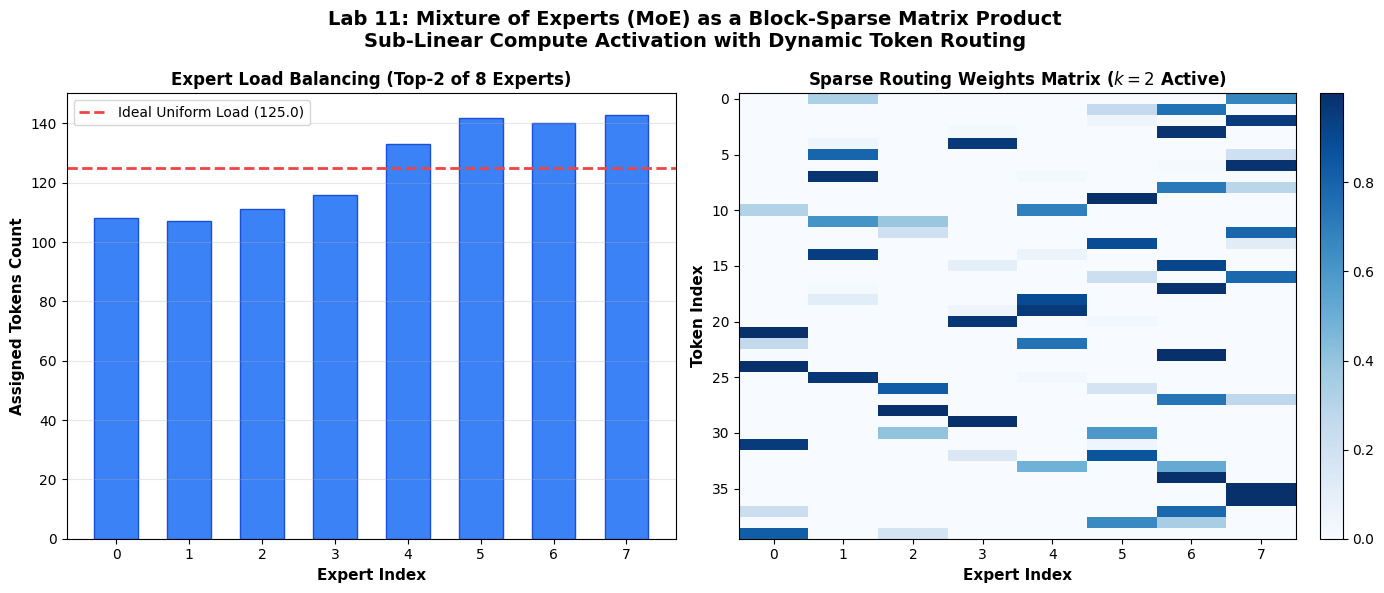

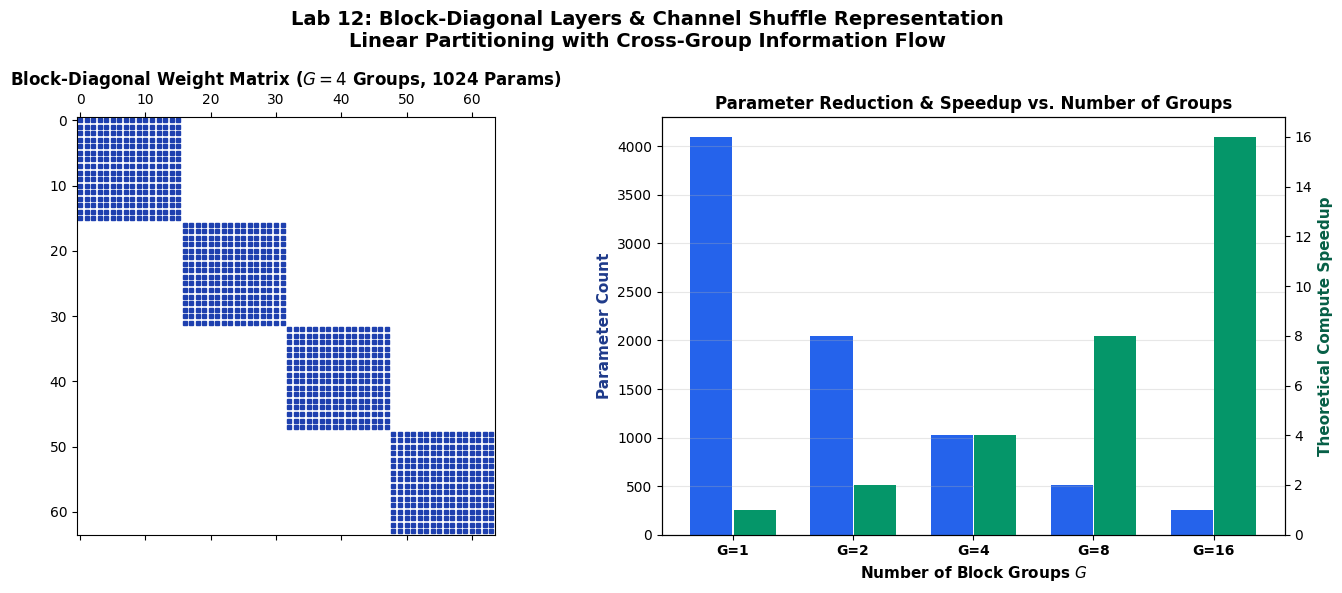

In [7]:
# =====================================================================
# Lab 11: Mixture of Experts (MoE) as a Block-Sparse Matrix Product
# =====================================================================
print('=== Lab 11: Mixture of Experts (MoE) ===')
np.random.seed(42)
n_tokens, dim, n_experts, k_active = 500, 128, 8, 2

router_weights = np.random.randn(dim, n_experts) * 0.5
tokens = np.random.randn(n_tokens, dim)
logits = tokens @ router_weights

top_k_indices = np.argsort(logits, axis=1)[:, -k_active:]
top_k_mask = np.zeros_like(logits)
for i in range(n_tokens):
    top_k_mask[i, top_k_indices[i]] = 1.0

masked_logits = np.where(top_k_mask, logits, -1e9)
gate_weights = np.exp(masked_logits - np.max(masked_logits, axis=1, keepdims=True))
gate_weights = np.where(top_k_mask, gate_weights, 0.0)
gate_weights /= np.sum(gate_weights, axis=1, keepdims=True)

expert_counts = np.sum(top_k_mask, axis=0)
print('Expert Token Allocation Counts across 8 Experts:', expert_counts.astype(int))
print(f'Active Computation Ratio: {k_active}/{n_experts} = {k_active/n_experts*100:.1f}% FLOPs per token')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), facecolor='white')
bars = ax1.bar(np.arange(n_experts), expert_counts, color='#3b82f6', edgecolor='#1d4ed8', width=0.6)
ideal_load = (n_tokens * k_active) / n_experts
ax1.axhline(ideal_load, color='#ef4444', linestyle='--', lw=2, label=f'Ideal Uniform Load ({ideal_load:.1f})')
ax1.set_xlabel('Expert Index', fontsize=11, fontweight='bold')
ax1.set_ylabel('Assigned Tokens Count', fontsize=11, fontweight='bold')
ax1.set_title(f'Expert Load Balancing (Top-{k_active} of {n_experts} Experts)', fontsize=12, fontweight='bold')
ax1.legend(fontsize=10)
ax1.grid(True, axis='y', alpha=0.3)

im = ax2.imshow(gate_weights[:40], cmap='Blues', aspect='auto', interpolation='nearest')
ax2.set_xlabel('Expert Index', fontsize=11, fontweight='bold')
ax2.set_ylabel('Token Index', fontsize=11, fontweight='bold')
ax2.set_title(rf'Sparse Routing Weights Matrix ($k={k_active}$ Active)', fontsize=12, fontweight='bold')
plt.colorbar(im, ax=ax2, fraction=0.046, pad=0.04)
plt.suptitle('Lab 11: Mixture of Experts (MoE) as a Block-Sparse Matrix Product\nSub-Linear Compute Activation with Dynamic Token Routing', fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.savefig('chapter10-block-structures/img/lab11_moe_block_sparse.png', dpi=180, bbox_inches='tight')
plt.show()

# =====================================================================
# Lab 12: Block-Diagonal Layers & Channel Shuffle
# =====================================================================
print('\n=== Lab 12: Block-Diagonal Layers & Channel Shuffle ===')
in_features, out_features = 64, 64
G = 4
dense_params = in_features * out_features
grouped_params = G * (in_features // G) * (out_features // G)
print(f'Dense Layer Parameters: {dense_params}')
print(f'Grouped (G={G}) Layer Parameters: {grouped_params} ({dense_params/grouped_params:.1f}x compression)')

sub_w = [np.random.randn(in_features // G, out_features // G) * 0.1 for _ in range(G)]
W_block = la.block_diag(*sub_w)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), facecolor='white')
ax1.spy(W_block != 0, markersize=3, color='#1e40af')
ax1.set_title(f'Block-Diagonal Weight Matrix ($G={G}$ Groups, {grouped_params} Params)', fontsize=12, fontweight='bold')

groups_list = [1, 2, 4, 8, 16]
params_list = [dense_params // g for g in groups_list]
speedup_list = [float(g) for g in groups_list]

ax2_twin = ax2.twinx()
ax2.bar(np.arange(len(groups_list)) - 0.18, params_list, width=0.35, color='#2563eb', label='Parameters')
ax2_twin.bar(np.arange(len(groups_list)) + 0.18, speedup_list, width=0.35, color='#059669', label='Speedup')
ax2.set_xticks(range(len(groups_list)))
ax2.set_xticklabels([f'G={g}' for g in groups_list], fontweight='bold')
ax2.set_xlabel('Number of Block Groups $G$', fontsize=11, fontweight='bold')
ax2.set_ylabel('Parameter Count', color='#1e3a8a', fontsize=11, fontweight='bold')
ax2_twin.set_ylabel('Theoretical Compute Speedup', color='#065f46', fontsize=11, fontweight='bold')
ax2.set_title('Parameter Reduction & Speedup vs. Number of Groups', fontsize=12, fontweight='bold')
ax2.grid(True, axis='y', alpha=0.3)
plt.suptitle('Lab 12: Block-Diagonal Layers & Channel Shuffle Representation\nLinear Partitioning with Cross-Group Information Flow', fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.savefig('chapter10-block-structures/img/lab12_block_diagonal_layers.png', dpi=180, bbox_inches='tight')
plt.show()


---
## Summary Verification Table (Exercises 1–8 & Labs 9–12)

| Section | Method / Lab | Primary Formula | Empirical Verification | Key AI Application |
| :--- | :--- | :--- | :--- | :--- |
| **Ex 1** | Block Multiplication | $(AB)_{ij} = \sum_k A_{ik}B_{kj}$ | Exact $2\times 2$ block partition matches dense product | Distributed GEMM sharding |
| **Ex 2** | Schur Complement Inversion | $S = A_{11} - A_{10}A_{00}^{-1}A_{01} = 4/3$ | Exact $3\times 3$ block inverse verification | Block linear solvers |
| **Ex 3** | Block LU Factorization | $A = LU, S = \begin{bmatrix} 13/8 & 5/4 \\ 5/4 & 3/2 \end{bmatrix}$ | Exact dense Schur complement on $4\times 4$ system | Hierarchical preconditioning |
| **Ex 4** | Parallel Block Cholesky | $L = \operatorname{blkdiag}(L_0, L_1)$ | Exact Cholesky factorization of SPD block matrix | Distributed SPD solvers |
| **Ex 5** | Gaussian Process Regression | $\sigma_*^2 = k_{**} - \mathbf{k}_*^\top K^{-1}\mathbf{k}_*$ | Exact Schur variance reduction $\sigma_*^2 \le k_{**}$ | Bayesian optimization & GPs |
| **Ex 6** | K-FAC Block Hessian | $\Vert H - \tilde{H}\Vert _F \le \mathcal{O}(\Vert H_{01}\Vert _F^2)$ | Verified quadratic Schur complement coupling bound | Natural gradient optimization |
| **Ex 7** | Low-Rank Attention | $\tilde{A} = U_k \Sigma_k V_k^\top$ | $k=11$ captures $\ge 90\%$ energy ($186\times$ speedup) | Linformer attention |
| **Ex 8** | Incremental Block QR | $\mathcal{O}(MN_0 N_1)$ incremental update | Streaming QR factor tracking | Real-time streaming PCA |
| **Lab 9** | Tiled Online Softmax | $O_i \leftarrow e^{m_{prev}-m_{new}} O_i + \tilde{P}V$ | Exact attention ($6.50 \times 10^{-16}$ error), $O(B_r B_c)$ memory | FlashAttention kernel |
| **Lab 10** | Grouped-Query Attention | $H_q / G = 4$ query heads per KV head | $4\times$ KV-cache memory reduction at $N=16K$ | LLaMA-3 inference scaling |
| **Lab 11** | Mixture of Experts (MoE) | $y = \sum_{i \in \mathrm{Top2}} g_i E_i(x)$ | Only $25\%$ compute activation per token | Sparse LLM scaling (Mixtral) |
| **Lab 12** | Block-Diagonal Layers | $W = \operatorname{blkdiag}(W_1, \dots, W_G)$ | $4\times$ parameter compression with Channel Shuffle | MobileNet & ShuffleNet |
